# Topic 1 - Training a neural network: PyTorch, and watching it overfit

**AI in Quantitative Biology (Univ. Milano, 2026) - supplementary notebook**

The classes use neural networks as finished tools: `MLPRegressor` in classes 1 and 2, a ready-made
training loop in class 3. This notebook opens the box from two sides.

* **How the learning is written.** Every model in PyTorch is built from four ideas - tensors,
  autograd, modules and an optimizer - and they are worth meeting on their own, before they are
  buried inside a model. `topic2` and `topic3` assume them.
* **How the learning behaves.** Class 1 Part 6 drew the training and test error of an oversized
  network epoch by epoch on the fish data. Here the same phenomena play out on a one-dimensional
  curve you can see, with sliders for width, depth, regularisation and the amount of data.

| Part | Topic | Time |
|---|---|---|
| 1 | PyTorch in ten minutes | 25 min |
| 2 | Playground: a neural network on a curve you can see | 20 min |

Everything runs on a laptop **CPU**. Exercises are marked ✏️ and open questions ❓; the answers are
in this notebook, right below - try before you read.

## Setup

The cell below is collapsed on purpose: it only contains imports, the data loader and a few
helpers. Run it and move on (click the title to unfold it if you are curious).

In [ ]:
# @title Setup: imports, data loading and helpers (run me)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RNG = 0                                      # fixed seed: everyone gets the same numbers
pd.set_option("display.precision", 3)


def find_data_dir():
    """$QBIO_DATA if set, else the `data/` folder of the course repository (here or above)."""
    if os.environ.get("QBIO_DATA"):
        return Path(os.environ["QBIO_DATA"])
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "data" / "targeting.tsv").exists():
            return p / "data"
    raise FileNotFoundError("Cannot find data/: run the notebook inside the course repository, "
                            "or set QBIO_DATA to the path of its data/ folder")


DATA_DIR = find_data_dir()
print("data from", DATA_DIR)


def load_targeting():
    """3600 protein N-termini (first 50 residues) labelled SP / mTP / other."""
    return pd.read_csv(DATA_DIR / "targeting.tsv", sep="\t")


def load_enzymes():
    """2047 enzymes with their EC class (1-6) and full sequence."""
    return pd.read_csv(DATA_DIR / "enzymes.tsv", sep="\t")


AA = "ACDEFGHIKLMNPQRSTVWY"                  # the 20 standard amino acids
AA_INDEX = {a: i for i, a in enumerate(AA)}

# Kyte-Doolittle hydropathy scale (positive = hydrophobic). Used only to *interpret* the models.
KYTE_DOOLITTLE = {
    "A": 1.8, "R": -4.5, "N": -3.5, "D": -3.5, "C": 2.5, "Q": -3.5, "E": -3.5,
    "G": -0.4, "H": -3.2, "I": 4.5, "L": 3.8, "K": -3.9, "M": 1.9, "F": 2.8,
    "P": -1.6, "S": -0.8, "T": -0.7, "W": -0.9, "Y": -1.3, "V": 4.2,
}
KD = np.array([KYTE_DOOLITTLE[a] for a in AA])


def aa_composition(seq):
    """Fraction of each of the 20 amino acids in `seq` (a 20-vector, sums to 1)."""
    v = np.zeros(20, dtype=np.float32)
    for a in seq:
        v[AA_INDEX[a]] += 1
    return v / max(len(seq), 1)


def one_hot(seq):
    """A length-L sequence -> an (L, 20) matrix of 0s with a single 1 per column."""
    m = np.zeros((len(seq), 20), dtype=np.float32)
    m[np.arange(len(seq)), [AA_INDEX[a] for a in seq]] = 1
    return m


def n_params(model):
    return sum(p.numel() for p in model.parameters())


data from /Users/toni/Sync/teaching/c-courses/2026 AI QBio/classes/data


In [ ]:
import torch
import torch.nn as nn

torch.manual_seed(RNG)
torch.set_num_threads(2)                     # keeps timings comparable between laptops
print("PyTorch", torch.__version__)

PyTorch 2.15.0


The examples use the data of **class 3**: 3600 protein N-termini (the first 50 residues) labelled
**SP** (signal peptide), **mTP** (mitochondrial transit peptide) or **other**. Each residue is
one-hot encoded, so a protein is a 50 × 20 matrix. As a reference model we fit the class 3 baseline
once with scikit-learn - amino-acid composition and logistic regression - on a fixed 75/25 split.

In [ ]:
tp = load_targeting()
LABELS = ["other", "SP", "mTP"]
display(tp.head(3))
print(tp["label"].value_counts().to_dict())
print(tp["nterm"].str.len().unique(), "residues per sequence")

,accession,entry_name,protein_name,organism,label,signal_len,nterm
0,A0A023PYC6,YA16A_YEAST,Putative uncharacterized membrane protein YAL0...,Saccharomyces cerevisiae,SP,25,MVSSFFMASTLLAISSCFNSSISRAKGYNDSLESESLEFDVVDVVD...
1,A0A075B6J1,LV537_HUMAN,Immunoglobulin lambda variable 5-37,Homo sapiens,SP,19,MAWTPLLLLLLSHCTGSLSQPVLTQPPSSSASPGESARLTCTLPSD...
2,A0A075B6J6,LV322_HUMAN,Immunoglobulin lambda variable 3-22,Homo sapiens,SP,20,MAWATLLLPLLNLYTGSVASYELTQLPSVSVSPGQTARITCSGDVL...


{'SP': 1200, 'mTP': 1200, 'other': 1200}
[50] residues per sequence


In [ ]:
X_all = torch.tensor(np.stack(tp["nterm"].map(one_hot)))      # (3600, 50, 20)
y_all = tp["label"].map({lab: i for i, lab in enumerate(LABELS)}).values
Y_all = torch.tensor(y_all)
print("X_all:", tuple(X_all.shape), " = proteins x positions x amino acids")
print(f"{X_all.numel():,} numbers, of which {int(X_all.sum()):,} are non-zero "
      f"({100 * X_all.mean():.0f}%)")

X_all: (3600, 50, 20)  = proteins x positions x amino acids
3,600,000 numbers, of which 180,000 are non-zero (5%)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

idx_train, idx_test = train_test_split(np.arange(len(tp)), test_size=0.25,
                                       stratify=y_all, random_state=RNG)
X_train, Y_train = X_all[idx_train], Y_all[idx_train]
X_test, Y_test = X_all[idx_test], Y_all[idx_test]

X_comp = np.vstack(tp["nterm"].map(aa_composition))           # (3600, 20)
logreg = LogisticRegression(max_iter=3000).fit(X_comp[idx_train], y_all[idx_train])
ACC_COMP = accuracy_score(y_all[idx_test], logreg.predict(X_comp[idx_test]))
print(f"composition (20 features) + logistic regression: test accuracy = {ACC_COMP:.3f}")

composition (20 features) + logistic regression: test accuracy = 0.802


## Part 1 - PyTorch in ten minutes

Slide 26 puts it exactly right: *"the concepts are relatively easy... implementation (e.g. gradients) is
not"*. A framework exists to close that gap. Every network in `topic2` and `topic3` is built from four PyTorch
ideas, and they are worth meeting on their own, before they are buried inside a model:

1. a **tensor** - a numpy array that can live on a GPU and remember where it came from;
2. **autograd** - the derivative of any computation, for free;
3. **`nn.Module`** - a function with parameters inside, so you describe the *topology* and nothing else;
4. an **optimizer** - the three lines that actually do the learning.

Nothing here is specific to proteins. If you have never written PyTorch, this is the section to keep.

### 1. Tensors

A `torch.Tensor` behaves like a numpy array - same indexing, same broadcasting, same `.shape` - with two
differences that matter: it can be moved to a GPU, and it can record the operations applied to it so the
gradient can be replayed backwards.

Two dtypes do almost all the work, and mixing them up is the most common beginner error: **inputs are
`float32`**, and **class labels are `int64`** (`long`). PyTorch's cross-entropy loss *demands* that.

In [ ]:
print("X_all :", tuple(X_all.shape), X_all.dtype, "  <- proteins x positions x amino acids")
print("Y_all :", tuple(Y_all.shape), Y_all.dtype, "  <- one class index per protein")

# indexing and reductions are numpy's
print("\nfirst protein, first 3 positions:\n", X_all[0, :3])
print("one-hot rows really sum to 1:", X_all[0].sum(dim=1)[:5].tolist())

# numpy <-> torch, no copy in either direction
a = np.arange(6, dtype=np.float32).reshape(2, 3)
t = torch.from_numpy(a)
print("\nnumpy -> torch:", t.shape, "| torch -> numpy:", t.numpy().shape)
print("matrix product:", (t @ t.T).tolist())

X_all : (3600, 50, 20) torch.float32   <- proteins x positions x amino acids
Y_all : (3600,) torch.int64   <- one class index per protein

first protein, first 3 positions:
 tensor([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0.,
         0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1.,
         0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0.,
         0., 0.]])
one-hot rows really sum to 1: [1.0, 1.0, 1.0, 1.0, 1.0]

numpy -> torch: torch.Size([2, 3]) | torch -> numpy: (2, 3)
matrix product: [[5.0, 14.0], [14.0, 50.0]]


### 2. Autograd: the derivative for free

In class 1 we differentiated the squared error by hand to write gradient descent. That is feasible for a
line and hopeless for a network, which is why slide 23 devotes itself to backpropagation.

PyTorch does it mechanically. Mark a tensor with `requires_grad=True`, compute *any* scalar from it, call
`.backward()`, and the derivative appears in `.grad`. Let us check it against the formula we derived by
hand in class 1: for $L = \frac{1}{n}\sum (wx_i - y_i)^2$, $\;\partial L/\partial w = \frac{2}{n}\sum (wx_i - y_i)x_i$.

In [ ]:
x = torch.tensor([1.0, 2.0, 3.0, 4.0])
y = torch.tensor([2.1, 3.9, 6.2, 7.8])

w = torch.tensor(0.5, requires_grad=True)     # the parameter we want the derivative for
loss = ((w * x - y) ** 2).mean()              # any computation at all, as long as it ends in a scalar
loss.backward()                               # walk the graph backwards

by_hand = (2 * ((0.5 * x - y) * x)).mean()
print(f"autograd  dL/dw = {w.grad.item():.4f}")
print(f"by hand   dL/dw = {by_hand.item():.4f}")

autograd  dL/dw = -22.3500
by hand   dL/dw = -22.3500


The same machinery gives the gradient of the 16-filter convolution of `topic2` with respect to all 2 947 of its weights,
and you never write a derivative again. This is the whole reason deep learning is practical.

### 3. `nn.Module`: a function with parameters inside

A layer is a function that carries its own weights. `nn.Linear(20, 3)` *is* the multinomial logistic
regression we just fitted with scikit-learn: it computes $xW^\top + b$, and it holds exactly the
3 × 20 + 3 = **63** parameters that model had.

In [ ]:
torch.manual_seed(RNG)
layer = nn.Linear(20, 3)                       # 20 amino-acid fractions in, 3 class scores out

v = torch.tensor(X_comp[:1])                   # one protein's composition
print("nn.Linear(v) =", layer(v).detach().numpy().round(4))
print("v @ W.T + b  =", (v @ layer.weight.T + layer.bias).detach().numpy().round(4))

print("\nparameters it owns:")
for name, prm in layer.named_parameters():
    print(f"  {name:>7s}  {tuple(prm.shape)}")
print("  total:", n_params(layer))

nn.Linear(v) = [[ 0.0987  0.0716 -0.1928]]
v @ W.T + b  = [[ 0.0987  0.0716 -0.1928]]

parameters it owns:
   weight  (3, 20)
     bias  (3,)
  total: 63


You build a network by composing such modules (`nn.Sequential`) or by subclassing `nn.Module` and writing
`forward()` - which is what every model in `topic2` and `topic3` does. You describe the **topology**; the gradients, the
parameter bookkeeping and the GPU transfers are not your problem. That is slide 26's "describe the
network topology (in code!)".

### 4. The training loop

Three lines do the learning, and they always come in this order:

```python
optimiser.zero_grad()   # throw away the previous step's gradients
loss.backward()         # accumulate d(loss)/d(parameter) into every .grad
optimiser.step()        # nudge every parameter downhill
```

Here is the entire thing, fitting logistic regression on the composition features - the same model
scikit-learn fitted above, now written out. `CrossEntropyLoss` is the classification counterpart of the
squared error from class 1; it takes **raw scores** (no softmax - it applies one internally) and
**int64** labels.

In [ ]:
X_comp_t = torch.tensor(X_comp)                       # (3600, 20) float32
Xc_tr, Yc_tr = X_comp_t[idx_train], Y_all[idx_train]
Xc_te, Yc_te = X_comp_t[idx_test], Y_all[idx_test]

torch.manual_seed(RNG)
model = nn.Linear(20, 3)
optimiser = torch.optim.Adam(model.parameters(), lr=0.05)
loss_fn = nn.CrossEntropyLoss()

for epoch in range(1, 301):
    loss = loss_fn(model(Xc_tr), Yc_tr)               # forward
    optimiser.zero_grad()
    loss.backward()                                   # backward
    optimiser.step()                                  # update
    if epoch % 100 == 0:
        with torch.no_grad():                         # no gradients needed just to look
            acc = (model(Xc_te).argmax(dim=1) == Yc_te).float().mean().item()
        print(f"epoch {epoch:3d}   loss {loss.item():.3f}   test accuracy {acc:.3f}")

print(f"\nscikit-learn, same features, same split: {ACC_COMP:.3f}")

epoch 100   loss 0.718   test accuracy 0.758
epoch 200   loss 0.600   test accuracy 0.788
epoch 300   loss 0.543   test accuracy 0.796

scikit-learn, same features, same split: 0.802


Same model, same data, essentially the same answer - 0.796 after 300 steps against scikit-learn's 0.802, and still creeping up - reached by walking downhill instead of by a
solver. From here on the
only thing that changes is what goes between the input and the three output scores - and that is exactly
what "architecture" means.

Two idioms in that loop deserve a note, because forgetting them is the classic silent bug:

- **`torch.no_grad()`** around evaluation. Without it PyTorch builds a graph it will never use: slower,
  and it holds memory.
- **`model.train()` / `model.eval()`**. Our models here behave identically in both modes, but dropout and
  batch normalisation do not, so the `train()` helper of `topic2` sets the mode every time.

❓ **Question.** What happens if you forget `optimiser.zero_grad()`?

In [ ]:
torch.manual_seed(RNG)
probe = nn.Linear(20, 3)
for step in range(1, 4):
    loss_fn(probe(Xc_tr), Yc_tr).backward()           # no zero_grad anywhere
    print(f"after {step} backward call(s): mean |gradient| = {probe.weight.grad.abs().mean():.5f}")

after 1 backward call(s): mean |gradient| = 0.00306
after 2 backward call(s): mean |gradient| = 0.00612
after 3 backward call(s): mean |gradient| = 0.00918


**Answer.** `.grad` **accumulates**: the magnitudes come out as 1×, 2×, 3× the same number. Nothing
crashes and no warning is printed - your model simply takes steps based on the sum of every gradient
since the start of time, and training quietly degrades. (The behaviour is deliberate: it is how you
simulate a large batch on a small GPU, by summing the gradients of several minibatches before stepping.)

The support cell of `topic2` wraps exactly the loop above into `train(model, ...)`, with minibatches
and a per-epoch accuracy record, so that there you can read the architectures and ignore the
plumbing.

## Part 2 - Playground: a neural network on a curve you can see

Class 1 Part 6 showed overfitting as two curves: the training error keeps falling while the test
error turns around. What the network is *doing* meanwhile is much easier to *see* in one dimension. We use a toy problem where the true
curve is known: a few noisy "measurements" of a dose-response-like curve. `mlp_playground()` trains an
MLP on them one epoch at a time and draws:
* **left**: the network's curve at several moments during training (light = early, dark = late);
* **right**: training and test error at every epoch. The dotted line is the noise level (the error of
  the true curve itself): no model can do better than that on new data.

Parameters: `width` and `layers` (network size), `alpha` (L2 penalty), `n_train` (number of points),
`noise`, `epochs`, `seed`.

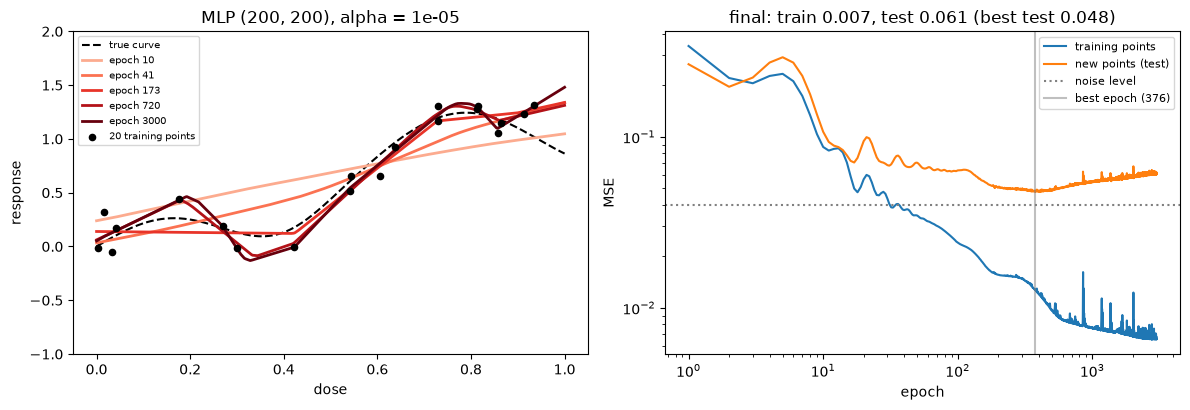

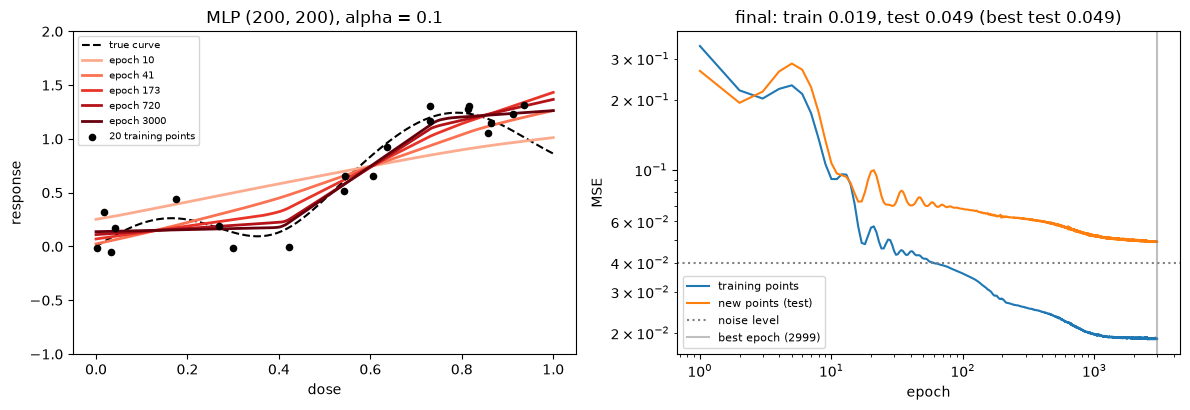

In [ ]:
# @title Support code: the MLP playground
def true_curve(x):
    """The 'truth' we pretend not to know: a smooth dose-response-like curve."""
    return 1 / (1 + np.exp(-15 * (x - 0.45))) + 0.25 * np.sin(10 * x)

def make_toy(n, noise, seed):
    """n noisy measurements of true_curve at random x in [0, 1]."""
    rng = np.random.default_rng(seed)
    x = np.sort(rng.uniform(0, 1, n))
    return x, true_curve(x) + rng.normal(0, noise, n)

from sklearn.neural_network import MLPRegressor
from sklearn.exceptions import ConvergenceWarning
import warnings

def mlp_playground(width=200, layers=2, alpha=1e-5, n_train=20, noise=0.2, epochs=3000, seed=0):
    x_tr, y_tr = make_toy(n_train, noise, seed)
    x_te, y_te = make_toy(500, noise, seed + 1000)
    grid = np.linspace(0, 1, 400)[:, None]
    net = MLPRegressor(hidden_layer_sizes=(width,) * layers, alpha=alpha,
                       learning_rate_init=0.003, random_state=seed)
    snap_epochs = sorted({int(e) for e in np.geomspace(10, epochs, 5)})
    tr_mse, te_mse, snaps = [], [], {}
    for epoch in range(1, epochs + 1):
        net.partial_fit(x_tr[:, None], y_tr)
        tr_mse.append(np.mean((net.predict(x_tr[:, None]) - y_tr) ** 2))
        te_mse.append(np.mean((net.predict(x_te[:, None]) - y_te) ** 2))
        if epoch in snap_epochs:
            snaps[epoch] = net.predict(grid)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
    ax1.plot(grid, true_curve(grid), "k--", lw=1.5, label="true curve")
    for i, (e, curve) in enumerate(snaps.items()):
        ax1.plot(grid, curve, color=plt.cm.Reds(0.3 + 0.7 * i / max(1, len(snaps) - 1)), lw=2, label=f"epoch {e}")
    ax1.scatter(x_tr, y_tr, color="k", s=20, zorder=3, label=f"{n_train} training points")
    ax1.set_ylim(-1, 2); ax1.set_xlabel("dose"); ax1.set_ylabel("response"); ax1.legend(fontsize=7, loc="upper left")
    ax1.set_title(f"MLP {(width,) * layers}, alpha = {alpha:g}")

    best = int(np.argmin(te_mse))
    ax2.plot(range(1, epochs + 1), tr_mse, label="training points")
    ax2.plot(range(1, epochs + 1), te_mse, label="new points (test)")
    ax2.axhline(noise ** 2, color="grey", ls=":", label="noise level")
    ax2.axvline(best + 1, color="grey", alpha=0.5, label=f"best epoch ({best + 1})")
    ax2.set_xscale("log"); ax2.set_yscale("log"); ax2.set_xlabel("epoch"); ax2.set_ylabel("MSE")
    ax2.set_title(f"final: train {tr_mse[-1]:.3f}, test {te_mse[-1]:.3f} (best test {te_mse[best]:.3f})")
    ax2.legend(fontsize=8)
    plt.tight_layout(); plt.show()

mlp_playground()
mlp_playground(alpha=0.1)

*Sliders:* in Jupyter or Colab with `ipywidgets` installed, the next cell shows sliders and redraws the figure when you release one. Without `ipywidgets`, just call the function with other values.

In [ ]:
# @title Sliders for the playground
try:
    from ipywidgets import interact, IntSlider, FloatSlider, FloatLogSlider
    interact(mlp_playground,
             width=IntSlider(value=200, min=2, max=500, step=2, continuous_update=False),
             layers=IntSlider(value=2, min=1, max=4, continuous_update=False),
             alpha=FloatLogSlider(value=1e-5, base=10, min=-6, max=1, continuous_update=False),
             n_train=IntSlider(value=20, min=10, max=300, step=5, continuous_update=False),
             noise=FloatSlider(value=0.2, min=0.0, max=0.6, step=0.05, continuous_update=False),
             epochs=IntSlider(value=3000, min=100, max=6000, step=100, continuous_update=False),
             seed=IntSlider(value=0, min=0, max=20, continuous_update=False))
except ImportError:
    print("ipywidgets is not installed: call mlp_playground(width=..., alpha=..., n_train=...) instead")

interactive(children=(IntSlider(value=200, continuous_update=False, description='width', max=500, min=2, step=…

✏️ **Exercise 2.1.** Use the playground to answer:
1. In the first figure, in what order does the network learn things? When does the test error start
   to rise?
2. What changes with `alpha=0.1` (second figure)? And with `alpha=1`?
3. Without regularisation, which helps more against overfitting: a smaller network (`width=8`) or
   more data (`n_train=200`)?
4. Try `seed=1, 2, 3` with the default settings. Do you always get the same curve?

**Answer.**
1. First the **coarse trend** (epoch 10: almost a straight line), then the S shape (≈ epoch 170), and
   finally the details of individual points: by epoch 3000 the curve dips too deep around dose 0.35
   and keeps rising at the right edge where the true curve comes down. The test error is lowest at
   epoch ≈ 380 (MSE 0.048, close to the noise level 0.04) and then rises to 0.061, while the training
   error keeps falling to 0.007, far *below* the noise level: the network is memorising noise.
   Early stopping at epoch ≈ 380 would keep the best network.
2. With `alpha=0.1` the weights cannot grow large enough for sharp bends: the curve stays smooth
   (it even smooths away the small bump at dose 0.2), and the test error keeps going *down* until the
   end (0.049): no early stopping needed. With `alpha=1` the penalty is too strong and the curve is
   too stiff to follow the S shape (test MSE ≈ 0.09): underfitting.
3. Both work here. `width=8` cannot memorise 20 points and ends at test MSE 0.048, like the best epoch
   of the big network. `n_train=200` reaches the noise level (0.040) with training and test error equal.
   More data is the more reliable cure: a network that is too small can also miss real structure.
4. No. Different random initial weights and a different sample of points give different curves,
   especially between and outside the points, and the best epoch moves too (≈ 135-380 for seeds 0-3).
   Neural networks do not have a unique solution; averaging several of them (an **ensemble**) is a
   common way to reduce this variance.

## Summary

* A PyTorch model is four ideas: **tensors** (inputs `float32`, labels `int64`), **autograd**
  (`.backward()` fills every `.grad`), **modules** (`nn.Linear(20, 3)` *is* a logistic regression
  with 63 parameters) and the **three-line loop** `zero_grad` / `backward` / `step`. Written out by
  hand it reproduces scikit-learn's answer (0.796 against 0.802).
* Forgetting `zero_grad()` raises no error and prints no warning: the gradients silently accumulate.
* A network learns the **coarse trend first** and the noise last. Past the best epoch the training
  error keeps falling below the noise level while the error on new points rises - overfitting.
  **Early stopping** (chosen on a validation set, never on the test set) or an L2 penalty stops it;
  too much penalty underfits instead.
* A smaller network or, more reliably, **more data** also cures overfitting, and different seeds
  give different curves - which is why people average several networks.

## References and data sources

* Paszke A, Gross S, Massa F, et al. (2019). PyTorch: an imperative style, high-performance deep
  learning library. *NeurIPS 32*. [arXiv:1912.01703](https://arxiv.org/abs/1912.01703)
* Rumelhart DE, Hinton GE, Williams RJ (1986). Learning representations by back-propagating errors.
  *Nature* 323:533-536. [doi:10.1038/323533a0](https://doi.org/10.1038/323533a0) — backpropagation,
  which autograd automates.
* `data/targeting.tsv`: reviewed entries of UniProtKB/Swiss-Prot; see `README.md` and `data_prep/`.
* Slides: `slides/ai-qbio-unimi_2026_r1.pdf`, Part I (optimisation, backpropagation, overfitting).